# Módulo 3. Tarefa 3. Previsão de cancelamento de clientes com bibliotecas de IA

Este notebook responde à __Tarefa 3__: implementar um modelo de machine learning com bibliotecas de IA. O conjunto de dados é o __Telco Customer Churn__, do Kaggle: uma tabela com os dados de __7 043 clientes de uma empresa de telecomunicações__ (serviços de telefone, internet e televisão).

Cada linha é um cliente. A última coluna, `Churn`, diz se o cliente __cancelou__ o serviço ("Yes") ou __ficou__ ("No"). O objetivo é ensinar um modelo a __prever quem cancela__ e perceber __porquê__.

O notebook segue as quatro partes do enunciado:

- __Parte 1:__ preparação e análise dos dados (Pandas e Matplotlib);
- __Parte 2:__ treino de um modelo com o Scikit-learn (regressão logística);
- __Parte 3:__ aplicação de uma biblioteca avançada (SHAP);
- __Parte 4:__ conclusões.

__Antes de correr:__ o ficheiro `WA_Fn-UseC_-Telco-Customer-Churn.csv` tem de estar __na mesma pasta__ deste notebook.

# Parte 1. Preparação e análise dos dados

#### Passo 1: instalar e importar as bibliotecas

Se o SHAP ainda não estiver instalado, a célula seguinte instala-o (se já estiver, não faz nada).

In [1]:
# Instala o SHAP, a biblioteca que explica as previsões dos modelos
%pip install shap

In [2]:
# Importa o NumPy, com o alias habitual np, para cálculos com arrays
import numpy as np

# Importa o pandas, com o alias habitual pd, para trabalhar com a tabela de clientes
import pandas as pd

# Importa o pyplot do matplotlib, com o alias habitual plt, para os gráficos
import matplotlib.pyplot as plt

# Importa do scikit-learn: a divisão treino/teste e o modelo de regressão logística
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Importa do scikit-learn as métricas de avaliação e a matriz de confusão
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Importa o SHAP, a biblioteca avançada que explica o modelo
import shap

# Aumenta a largura de impressão das tabelas, para as colunas não serem cortadas em várias linhas
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

print("Bibliotecas importadas com sucesso.")

Bibliotecas importadas com sucesso.


#### Passo 2: carregar e explorar os dados

Carrega-se o ficheiro CSV com o pandas. O resultado é um __DataFrame__ (uma tabela) a que se chama `clientes`.

In [3]:
# Carrega o ficheiro CSV para um DataFrame
clientes = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Mostra o número de linhas (clientes) e de colunas
numero_linhas, numero_colunas = clientes.shape
print(f"Número de clientes (linhas): {numero_linhas}")
print(f"Número de colunas: {numero_colunas}")

# Mostra os primeiros 5 clientes
print("\nPrimeiros 5 clientes:")
print(clientes.head())

Número de clientes (linhas): 7043
Número de colunas: 21

Primeiros 5 clientes:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies  \
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No   
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL            Yes           No              Yes          No          No              No   
2  3668-QPYBK    Male              0      No         No       2          Yes                No             DSL            Yes          Yes               No          No          No              No   
3  7795-CFOCW    Male              0      No         No      45           No  No phone service             DSL            Yes

In [4]:
# Mostra o tipo de cada coluna e quantos valores não nulos tem
print("Informação sobre as colunas:\n")
clientes.info()

Informação sobre as colunas:

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 

In [5]:
# Estatísticas descritivas das colunas numéricas (média, mínimo, máximo, quartis)
print("Estatísticas descritivas das colunas numéricas:\n")
print(clientes.describe())

Estatísticas descritivas das colunas numéricas:

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


#### Passo 3: valores em falta

Primeiro verifica-se se há valores nulos. Depois repara-se que a coluna `TotalCharges` (total pago pelo cliente) aparece como __texto__ (`object`) e não como número. A função `pd.to_numeric` com `errors="coerce"` converte a coluna em números e transforma o que não é número em valor nulo (`NaN`), e assim já se consegue encontrar.

In [6]:
# Verifica os valores nulos de cada coluna, tal como lidos do ficheiro
print("Valores nulos por coluna (antes da conversão):")
print(clientes.isnull().sum().sum(), "valores nulos no total")

# Converte TotalCharges para número; o que não for número (espaço em branco) passa a nulo (NaN)
clientes["TotalCharges"] = pd.to_numeric(clientes["TotalCharges"], errors="coerce")

# Verifica outra vez os valores nulos
print("\nValores nulos por coluna (depois da conversão):")
print(clientes.isnull().sum()[clientes.isnull().sum() > 0])

Valores nulos por coluna (antes da conversão):
0 valores nulos no total

Valores nulos por coluna (depois da conversão):
TotalCharges    11
dtype: int64


In [7]:
# Mostra os clientes com TotalCharges em falta: todos têm tenure 0 (acabaram de chegar, ainda não pagaram nada)
clientes_sem_total = clientes[clientes["TotalCharges"].isnull()]
print(f"Clientes com TotalCharges em falta: {len(clientes_sem_total)}\n")
print(clientes_sem_total[["customerID", "tenure", "Contract", "MonthlyCharges", "Churn"]])

Clientes com TotalCharges em falta: 11

      customerID  tenure  Contract  MonthlyCharges Churn
488   4472-LVYGI       0  Two year           52.55    No
753   3115-CZMZD       0  Two year           20.25    No
936   5709-LVOEQ       0  Two year           80.85    No
1082  4367-NUYAO       0  Two year           25.75    No
1340  1371-DWPAZ       0  Two year           56.05    No
3331  7644-OMVMY       0  Two year           19.85    No
3826  3213-VVOLG       0  Two year           25.35    No
4380  2520-SGTTA       0  Two year           20.00    No
5218  2923-ARZLG       0  One year           19.70    No
6670  4075-WKNIU       0  Two year           73.35    No
6754  2775-SEFEE       0  Two year           61.90    No


In [8]:
# Apaga as linhas com valores em falta (são poucas e são clientes sem histórico de pagamentos)
clientes = clientes.dropna()

# Reinicia os índices, para ficarem seguidos (0, 1, 2, ...)
clientes = clientes.reset_index(drop=True)

print(f"Número de clientes depois de apagar as linhas em falta: {len(clientes)}")
print(f"Valores nulos que restam: {clientes.isnull().sum().sum()}")

Número de clientes depois de apagar as linhas em falta: 7032
Valores nulos que restam: 0


#### Passo 4: analisar a variável a prever (`Churn`)

A coluna `Churn` é o __alvo__. Vê-se quantos clientes cancelaram e quantos ficaram. Cria-se ainda a coluna `cancelou`, com 1 para quem cancelou e 0 para quem ficou, porque os modelos precisam de números.

In [9]:
# Conta quantos clientes cancelaram (Yes) e quantos ficaram (No)
contagem_churn = clientes["Churn"].value_counts()
print("Número de clientes por valor de Churn:")
print(contagem_churn)

# Calcula a percentagem de cada grupo
percentagem_cancelaram = contagem_churn["Yes"] / len(clientes) * 100
percentagem_ficaram = contagem_churn["No"] / len(clientes) * 100
print(f"\nCancelaram: {percentagem_cancelaram:.1f}%")
print(f"Ficaram: {percentagem_ficaram:.1f}%")

# Cria a coluna numérica cancelou: 1 se Churn é "Yes", 0 se é "No"
clientes["cancelou"] = (clientes["Churn"] == "Yes").astype(int)

Número de clientes por valor de Churn:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Cancelaram: 26.6%
Ficaram: 73.4%


#### Passo 5: gráficos para compreender os dados

Criam-se __três gráficos__ com o Matplotlib:

1. quantos clientes cancelaram e quantos ficaram;
2. a taxa de cancelamento por tipo de contrato;
3. há quanto tempo eram clientes (`tenure`), para quem cancelou e para quem ficou.

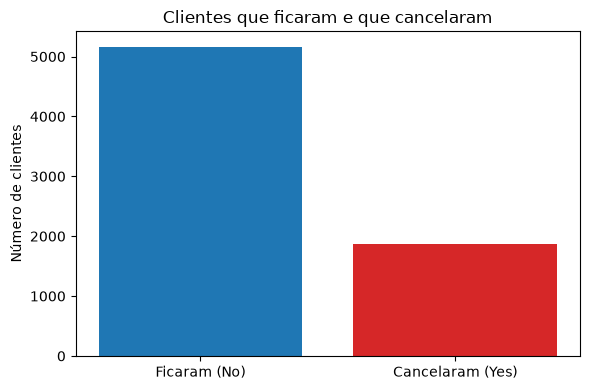

In [10]:
# Gráfico 1: número de clientes que ficaram e que cancelaram
plt.figure(figsize=(6, 4))
plt.bar(["Ficaram (No)", "Cancelaram (Yes)"], [contagem_churn["No"], contagem_churn["Yes"]], color=["tab:blue", "tab:red"])
plt.title("Clientes que ficaram e que cancelaram")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

Taxa de cancelamento por tipo de contrato (%):
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: cancelou, dtype: float64


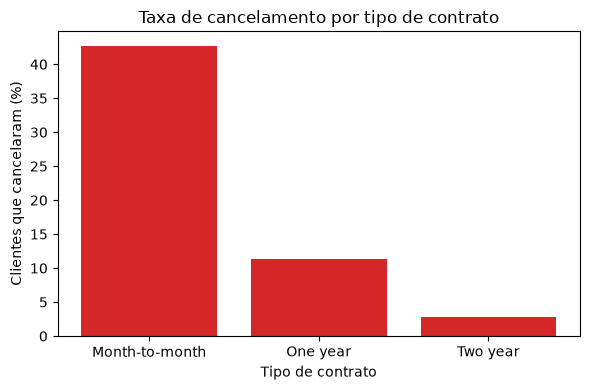

In [11]:
# Gráfico 2: taxa de cancelamento (%) por tipo de contrato
# A média da coluna cancelou (0 ou 1) dá a proporção de clientes que cancelaram em cada grupo
taxa_cancelamento_por_contrato = clientes.groupby("Contract")["cancelou"].mean() * 100
print("Taxa de cancelamento por tipo de contrato (%):")
print(taxa_cancelamento_por_contrato.round(1))

plt.figure(figsize=(6, 4))
plt.bar(taxa_cancelamento_por_contrato.index, taxa_cancelamento_por_contrato.values, color="tab:red")
plt.title("Taxa de cancelamento por tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Clientes que cancelaram (%)")
plt.tight_layout()
plt.show()

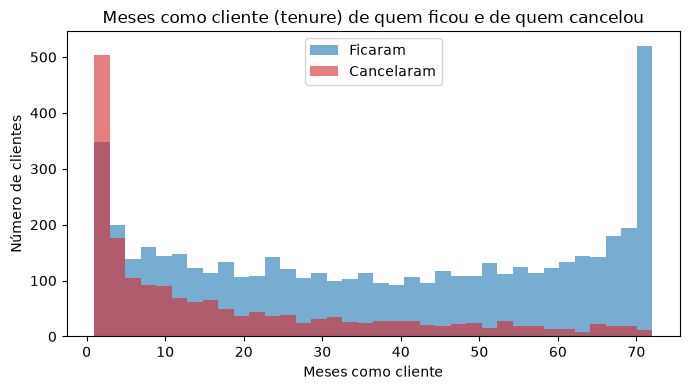

In [12]:
# Gráfico 3: há quantos meses eram clientes (tenure), para quem ficou e para quem cancelou
tenure_ficaram = clientes[clientes["cancelou"] == 0]["tenure"]
tenure_cancelaram = clientes[clientes["cancelou"] == 1]["tenure"]

plt.figure(figsize=(7, 4))
plt.hist(tenure_ficaram, bins=36, alpha=0.6, label="Ficaram", color="tab:blue")
plt.hist(tenure_cancelaram, bins=36, alpha=0.6, label="Cancelaram", color="tab:red")
plt.title("Meses como cliente (tenure) de quem ficou e de quem cancelou")
plt.xlabel("Meses como cliente")
plt.ylabel("Número de clientes")
plt.legend()
plt.tight_layout()
plt.show()

# Parte 2. Treino de um modelo com o Scikit-learn

#### Passo 1: preparar as variáveis

O modelo só trabalha com __números__, mas muitas colunas são texto (por exemplo "Yes"/"No" ou o tipo de contrato). A função `pd.get_dummies` resolve isto: __cria uma coluna nova de 0 e 1 por cada categoria__. Por exemplo, a coluna `Contract` (com "Month-to-month", "One year" e "Two year") passa a ter as colunas `Contract_One year` e `Contract_Two year`, com 1 quando o cliente tem esse contrato. Com `drop_first=True` guarda-se uma categoria a menos por coluna, porque a que falta já se deduz das outras (se não é "One year" nem "Two year", é mensal).

O `customerID` é só um código do cliente, não ajuda a prever nada, por isso fica de fora. A coluna `Churn` também fica de fora das variáveis, porque é a resposta que se quer prever.

In [13]:
# Variáveis (características) que o modelo vai usar: todas menos o código do cliente, o Churn e a coluna cancelou
caracteristicas = clientes.drop(columns=["customerID", "Churn", "cancelou"])

# Converte as colunas de texto em colunas de 0 e 1 (uma por categoria)
caracteristicas = pd.get_dummies(caracteristicas, drop_first=True, dtype=int)

# O alvo é a coluna cancelou (1 = cancelou, 0 = ficou)
alvo = clientes["cancelou"]

print(f"Número de colunas depois do get_dummies: {caracteristicas.shape[1]}")
print("\nNomes das colunas:")
print(list(caracteristicas.columns))

Número de colunas depois do get_dummies: 30

Nomes das colunas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


#### Passo 2: dividir em treino e teste

Os clientes dividem-se em __80% para treino__ e __20% para teste__. A divisão é feita com `train_test_split`:

- `test_size=0.2`: 20% para teste;
- `random_state=90`: fixa a semente do sorteio, para o resultado ser sempre o mesmo;
- `stratify=alvo`: mantém a __mesma proporção de cancelamentos__ no treino e no teste.

In [14]:
# Divide as características e o alvo em treino (80%) e teste (20%)
# X_treino e X_teste são as características; y_treino e y_teste são as respostas certas (cancelou ou não)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    caracteristicas, alvo, test_size=0.2, random_state=90, stratify=alvo
)

print(f"Clientes de treino: {len(X_treino)}")
print(f"Clientes de teste: {len(X_teste)}")
print(f"Percentagem de cancelamentos no treino: {y_treino.mean() * 100:.1f}%")
print(f"Percentagem de cancelamentos no teste: {y_teste.mean() * 100:.1f}%")

Clientes de treino: 5625
Clientes de teste: 1407
Percentagem de cancelamentos no treino: 26.6%
Percentagem de cancelamentos no teste: 26.6%


#### Passo 3: treinar o modelo

O modelo é uma __regressão logística__. Em termos simples: aprende com os clientes de treino e dá a cada característica um __peso__. Para um cliente novo calcula a __probabilidade de cancelar__ e, acima de 50%, prevê que cancela. O parâmetro `max_iter=5000` dá-lhe mais tentativas para encontrar os melhores pesos. Com as 1000 tentativas do curso o modelo não chegava ao fim e o scikit-learn avisava que não tinha convergido; com 5000 converge.

In [15]:
# Cria o modelo de regressão logística
modelo_cancelamento = LogisticRegression(max_iter=5000)

# Treina o modelo apenas com os dados de treino
modelo_cancelamento.fit(X_treino, y_treino)

# Faz a previsão para os clientes de teste (1 = cancela, 0 = fica)
previsoes_teste = modelo_cancelamento.predict(X_teste)

print("Modelo treinado.")
print(f"Previsões feitas para {len(previsoes_teste)} clientes de teste.")

Modelo treinado.
Previsões feitas para 1407 clientes de teste.


#### Passo 4: avaliar o modelo

In [16]:
# Calcula as métricas com os clientes de teste
exatidao_teste = accuracy_score(y_teste, previsoes_teste)
precisao_teste = precision_score(y_teste, previsoes_teste)
recall_teste = recall_score(y_teste, previsoes_teste)
f1_teste = f1_score(y_teste, previsoes_teste)

print("Métricas no conjunto de teste:")
print(f"Accuracy (exatidão): {exatidao_teste:.3f}")
print(f"Precision (precisão): {precisao_teste:.3f}")
print(f"Recall (sensibilidade): {recall_teste:.3f}")
print(f"F1-score: {f1_teste:.3f}")

# Compara a accuracy de treino com a de teste (se forem próximas, não há sobreajuste evidente)
exatidao_treino = modelo_cancelamento.score(X_treino, y_treino)
print(f"\nAccuracy no treino: {exatidao_treino:.3f}")
print(f"Accuracy no teste: {exatidao_teste:.3f}")

# Accuracy de um modelo "preguiçoso" que dissesse sempre que o cliente fica
exatidao_sempre_fica = 1 - y_teste.mean()
print(f"\nAccuracy de um modelo que diz sempre 'fica': {exatidao_sempre_fica:.3f}")

Métricas no conjunto de teste:
Accuracy (exatidão): 0.802
Precision (precisão): 0.640
Recall (sensibilidade): 0.588
F1-score: 0.613

Accuracy no treino: 0.807
Accuracy no teste: 0.802

Accuracy de um modelo que diz sempre 'fica': 0.734


In [17]:
# Relatório de classificação completo (precision, recall, f1-score e support de cada classe)
print("Relatório de classificação (0 = ficou, 1 = cancelou):\n")
print(classification_report(y_teste, previsoes_teste))

Relatório de classificação (0 = ficou, 1 = cancelou):

              precision    recall  f1-score   support

           0       0.86      0.88      0.87      1033
           1       0.64      0.59      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



Matriz de confusão [[TN, FP], [FN, TP]]:
[[909 124]
 [154 220]]


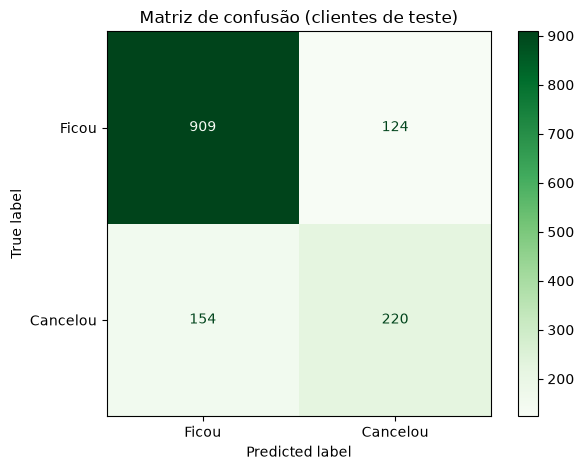

In [18]:
# Matriz de confusão: linhas = valores reais, colunas = valores previstos
matriz_confusao = confusion_matrix(y_teste, previsoes_teste)
print("Matriz de confusão [[TN, FP], [FN, TP]]:")
print(matriz_confusao)

# Desenha a matriz de confusão
visualizacao_matriz = ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Ficou", "Cancelou"])
visualizacao_matriz.plot(cmap="Greens")
plt.title("Matriz de confusão (clientes de teste)")
plt.tight_layout()
plt.show()

# Parte 3. Aplicação de uma biblioteca avançada: SHAP

O modelo prevê, mas não diz __porquê__. O __SHAP__ (SHapley Additive exPlanations) é uma abordagem da teoria dos jogos que explica o contributo de __cada característica__ para a previsão. Cada valor SHAP diz quanto uma característica __empurrou__ a previsão de um cliente para cima (mais probabilidade de cancelar) ou para baixo (menos probabilidade). Somados ao valor base, dão a previsão final.

Nota: no modelo de regressão logística, estes valores estão na escala dos "log-odds", não em percentagem. O que interessa é o __sinal__ (positivo empurra para cancelar, negativo para ficar) e o __tamanho__ do valor.

#### Passo 1: criar o explicador e calcular os valores SHAP

In [19]:
# Cria o explicador SHAP para o modelo, usando os dados de treino como referência
explicador = shap.Explainer(modelo_cancelamento, X_treino)

# Calcula os valores SHAP para os clientes de teste
valores_shap = explicador(X_teste)

print(f"Valores SHAP calculados para {valores_shap.values.shape[0]} clientes e {valores_shap.values.shape[1]} características.")

Background dataset has 5625 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5625 when initializing the masker.


Valores SHAP calculados para 1407 clientes e 30 características.


O SHAP pode mostrar uma mensagem a dizer que reduziu os dados de referência a 100 amostras. É normal: usa 100 clientes de treino como referência, para o cálculo ficar mais rápido. Por isso os valores SHAP são aproximados.

#### Passo 2: visão geral das características mais importantes

O gráfico __beeswarm__ (enxame de pontos) mostra cada cliente de teste como um ponto. As características estão ordenadas da mais importante (em cima) para a menos importante. Na horizontal, um ponto à __direita__ empurra a previsão para __cancelar__ e à __esquerda__ para __ficar__. A cor é o valor da característica: __vermelho__ = valor alto, __azul__ = valor baixo.

In [20]:
# Importância média de cada característica: média do valor absoluto do SHAP em todos os clientes de teste
importancia_media = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=X_teste.columns)
print("As 10 características mais importantes (média do valor absoluto do SHAP):")
print(importancia_media.sort_values(ascending=False).head(10).round(3))

As 10 características mais importantes (média do valor absoluto do SHAP):
tenure                            1.256
TotalCharges                      0.545
Contract_Two year                 0.500
InternetService_Fiber optic       0.347
Contract_One year                 0.241
TechSupport_Yes                   0.176
PaperlessBilling_Yes              0.175
OnlineSecurity_Yes                0.175
PaymentMethod_Electronic check    0.159
MultipleLines_Yes                 0.095
dtype: float64


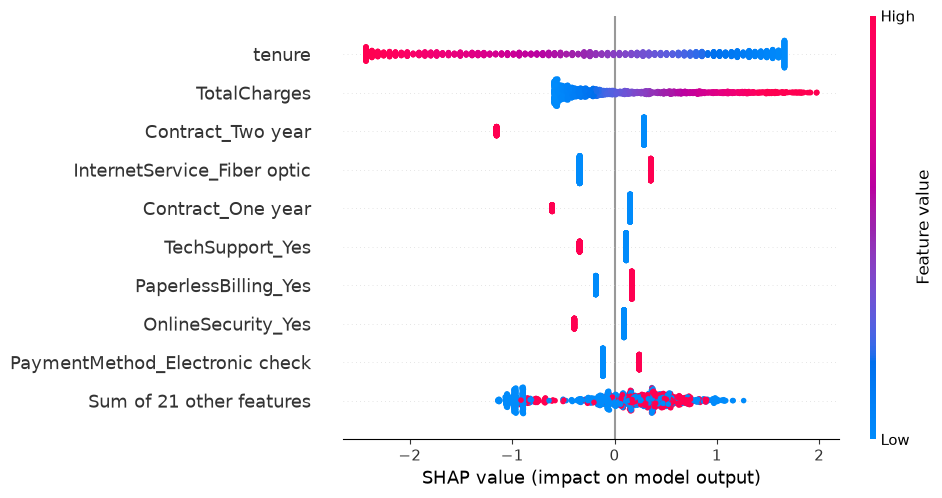

In [21]:
# Gráfico beeswarm das 10 características mais importantes
shap.plots.beeswarm(valores_shap, max_display=10)

#### Passo 3: explicar clientes concretos (force plot)

O __force plot__ mostra, para __um cliente__, como cada característica empurra a previsão. As setas vermelhas empurram para __cancelar__ e as azuis para __ficar__, a partir do valor base (a previsão média do modelo). Escolhem-se dois clientes de teste: o que o modelo considera __mais provável de cancelar__ e o __menos provável__.

In [22]:
# Calcula a probabilidade de cancelar de cada cliente de teste (coluna 1 = probabilidade de cancelar)
probabilidades_cancelar = modelo_cancelamento.predict_proba(X_teste)[:, 1]

# Posições do cliente com maior e com menor probabilidade de cancelar
posicao_mais_provavel_cancelar = int(np.argmax(probabilidades_cancelar))
posicao_menos_provavel_cancelar = int(np.argmin(probabilidades_cancelar))

print(f"Cliente mais provável de cancelar: probabilidade de {probabilidades_cancelar[posicao_mais_provavel_cancelar] * 100:.1f}% "
      f"(cancelou mesmo? {'sim' if y_teste.iloc[posicao_mais_provavel_cancelar] == 1 else 'não'})")
print(f"Cliente menos provável de cancelar: probabilidade de {probabilidades_cancelar[posicao_menos_provavel_cancelar] * 100:.1f}% "
      f"(cancelou mesmo? {'sim' if y_teste.iloc[posicao_menos_provavel_cancelar] == 1 else 'não'})")

Cliente mais provável de cancelar: probabilidade de 84.0% (cancelou mesmo? sim)
Cliente menos provável de cancelar: probabilidade de 0.1% (cancelou mesmo? não)


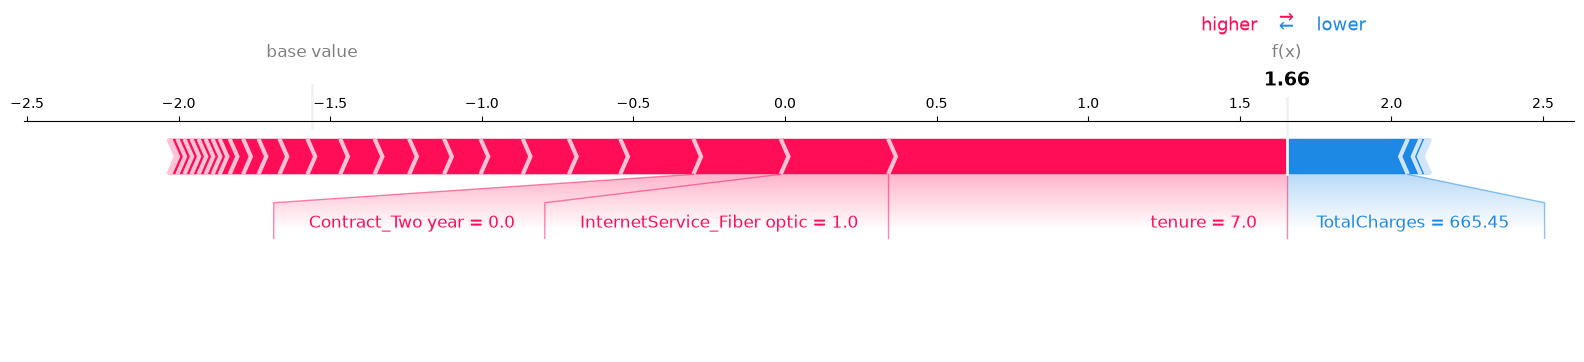

In [23]:
# Force plot do cliente mais provável de cancelar
# contribution_threshold=0.1 esconde as características com contributo muito pequeno, para o gráfico não ficar cheio de texto
shap.plots.force(valores_shap[posicao_mais_provavel_cancelar], matplotlib=True, figsize=(20, 3), contribution_threshold=0.1)

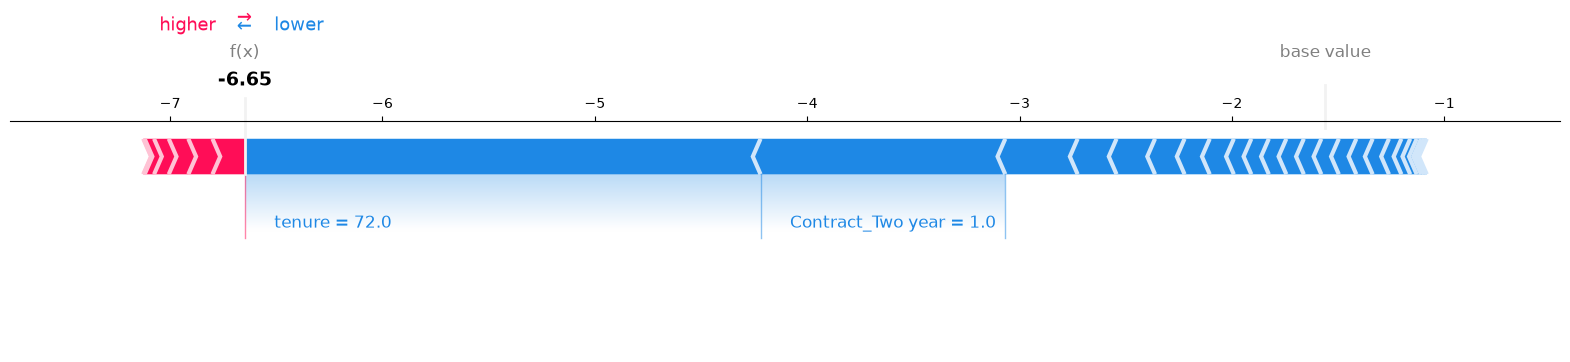

In [24]:
# Force plot do cliente menos provável de cancelar
shap.plots.force(valores_shap[posicao_menos_provavel_cancelar], matplotlib=True, figsize=(20, 3), contribution_threshold=0.1)

#### Passo 4: um cuidado ao interpretar os valores SHAP

Algumas características dizem quase a mesma coisa. Por exemplo, o total pago (`TotalCharges`) cresce com os meses de cliente (`tenure`), e o preço mensal (`MonthlyCharges`) é mais alto nos clientes com fibra ótica. Quando duas características estão muito ligadas, o modelo reparte a importância entre elas e o valor SHAP de cada uma, __sozinha__, pode ser enganador. A célula seguinte mede essa ligação (correlação, de -1 a 1; quanto mais perto de 1, mais ligadas).

In [25]:
# Correlação entre pares de características que "dizem quase a mesma coisa" (clientes de teste)
correlacao_tenure_total = X_teste["tenure"].corr(X_teste["TotalCharges"])
correlacao_mensal_fibra = X_teste["MonthlyCharges"].corr(X_teste["InternetService_Fiber optic"])

print(f"Correlação entre tenure e TotalCharges: {correlacao_tenure_total:.2f}")
print(f"Correlação entre MonthlyCharges e InternetService_Fiber optic: {correlacao_mensal_fibra:.2f}")

Correlação entre tenure e TotalCharges: 0.82
Correlação entre MonthlyCharges e InternetService_Fiber optic: 0.79


# Parte 4. Conclusões

#### O que foi feito

- Carregaram-se os dados de __7 043 clientes__. Apagaram-se __11__ com `TotalCharges` em branco (clientes novos, sem pagamentos), e ficaram __7 032__, dos quais __1 869 cancelaram (26,6%)__.
- O cancelamento depende muito do __tipo de contrato__ (42,7% no mensal, 11,3% no de um ano e 2,8% no de dois anos) e concentra-se nos __primeiros meses__ como cliente.
- Treinou-se uma __regressão logística__ (80% treino, 20% teste) e usou-se o __SHAP__ para a explicar.

#### Resultados do modelo (clientes de teste)

- __Accuracy: 0,802__ (0,807 no treino, sem sobreajuste evidente), contra 0,734 de um modelo que dissesse sempre "fica". O ganho é pequeno.
- __Precision: 0,640, recall: 0,588 e F1-score: 0,613.__ Dos 374 clientes que cancelaram, o modelo apanhou 220 e falhou 154 (matriz: 909, 124, 154 e 220).
- O modelo é razoável, mas __perde quatro em cada dez cancelamentos__, que é o erro que mais custa a uma empresa que quer evitar a saída de clientes.

#### O que o SHAP confirma

- A `tenure` é a característica mais importante (mais meses empurram para __ficar__), seguida do `TotalCharges`, do contrato de dois anos e da fibra ótica (que empurra para __cancelar__).
- __Cuidado:__ `tenure` e `TotalCharges` estão muito ligadas (correlação 0,82), tal como o preço mensal e a fibra ótica (0,79). Por isso o sinal de uma característica __sozinha__ não deve ser lido como causa. O SHAP explica __o modelo__, não a vida real.

#### Limitações

- Os dados são um conjunto de exemplo do Kaggle e o modelo é simples (relações em linha reta).
- Foi feita uma só divisão treino/teste, por isso com outra semente os valores mudariam um pouco.
- O limiar de decisão ficou nos 50%, e as classes (só 26,6% cancelam) foram tratadas apenas com o `stratify`.
- O SHAP usou 100 clientes de referência, por isso os valores são aproximados, e o ranking pode variar um pouco entre instalações.

#### Como poderia ser melhorado

- __Apanhar mais cancelamentos:__ baixar o limiar de decisão (por exemplo, para 40%) ou dar mais peso aos cancelamentos no treino (parâmetro `class_weight` do scikit-learn), à custa de mais falsos alarmes. Não foi testado, e a escolha depende do custo de cada erro para a empresa.
- __Testar outros modelos__ do curso (árvore de decisão, random forest) e comparar com a validação cruzada (K-fold).
- __Reduzir características repetidas__ (como `TotalCharges`) e __juntar mais informação__ sobre o comportamento dos clientes (reclamações, chamadas ao apoio).